In [10]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
#Plot spectres 
from scipy import signal
from scipy import fft
import netCDF4


## Annex 3-A - CEN4 + BILAP = UBS (UP3)

## Aim of Tutorial

The aim of this tutorial is to prove that the CEN4 combined with a Bi-Laplacian diffusion is equivalent to the UBS scheme.

To better understand this demonstrator you should follow Demonstrator 3 beforehand.

## Running the simulations


To run the simulation we need to run a CEN4+BILAP simulation and a UBS simulation in the case of the saltblock. You can do so yourself under the experience names ```cn_exp``` = ```CANAL_saltblock_blp_cen4``` and ```CANAL_saltblock_ubs``` __or you can execute the cell below.__

In [11]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00

cd /"$DIR"

rm CANAL_saltblock_blp_cen4_all_grid.nc
rm CANAL_saltblock_ubs_all_grid.nc

chmod -R a+x /"$DIR"/annex1_cfg/

bash /"$DIR"/annex3_cfg/annex3A.sh "$DIR"

+ set -v
set -u #Turn on error if using unset variables
+ set -u

if [ $# -lt 1 ]; then
    echo "Usage: $0 /path/to/the/directory"
    exit 1
fi
+ '[' 1 -lt 1 ']'

DIR="$1"
+ DIR=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00
SRC="$DIR/namelist_cfg"
+ SRC=/net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg

if [ ! -f "$SRC" ]; then
    echo "Erreur : fichier introuvable : $SRC"
    exit 1
fi
+ '[' '!' -f /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg ']'





SED_EXPR=(
-e 's/rn_domszx.*=.*\!/rn_domszx        =       1000.    !/'
-e 's/rn_domszy.*=.*\!/rn_domszy        =       1000.   !/'
-e 's/rn_domszz.*=.*\!/rn_domszz        =       1000.  !/'
-e 's/rn_dx.*=.*\!/rn_dx        =       20.     !/'
-e 's/rn_dy.*=.*\!/rn_dy        =       20.  !/'
-e 's/rn_dz.*=.*\!/rn_dz        =       1000.  !/'
-e 's/rn_0xratio.*=.*\!/rn_0xratio      =       0.5  !/'
-e 's/rn_0yratio.*=.*\!/rn_0yratio      =       0.5  !/'
-e 's/nn_fcase.*=.*\!/nn_fcase  =       0  !/'
-e 's/rn_ppgphi0.*=.*\!/rn_ppgphi0      =       38.5  !/'
-e 's/rn_u10.*=.*\!/rn_u10      =       0.  !/'
-e 's/rn_uzonal.*=.*\!/rn_uzonal        =       0.5  !/'
-e 's/rn_ujetszx.*=.*\!/rn_ujetszx              =       1000.  !/'
-e 's/rn_ujetszy.*=.*\!/rn_ujetszy              =       1000.  !/'
-e 's/nn_botcase.*=.*\!/nn_botcase      =       0  !/'
-e 's/nn_initcase.*=.*\!/nn_initcase    =     1       !/'
-e 's/ln_sshnoise.*=.*\!/ln_sshnoise    =       .false.   !/'
-e 's/ln_Iperio.*=.*\

rn_salszx, rn_salszy already in the file, insertion ignored.





diff "$SRC" "$SRC.bak"
+ diff /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg /net/pyxis/data/nemo/jbuisson/ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/namelist_cfg.bak


sed -i.bak \
-e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .true.  !/' \
-e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/' \
-e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/' \
-e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' \
-e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .false. !/' \
-e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' \
-e 's/nn_cen_h.*=.*\!/nn_cen_h  =       4               !/' \
-e 's/nn_cen_v.*=.*\!/nn_cen_v  =       4               !/' \
-e "s/cn_exp.*=.*'.*'/cn_exp =  'CANAL_saltblock_blp_cen4'      /" \
-e 's/ln_traldf_OFF.*=.*\!/ln_traldf_OFF        =       .false. !/' \
-e 's/ln_traldf_lap.*=.*\!/ln_traldf_lap        =       .false. !/' \

57c57
<    cn_exp    =       'CANAL_saltblock'            	 !  experience name
---
>    cn_exp =  'CANAL_saltblock_ubs'            	 !  experience name
57c57
<    cn_exp =  'CANAL_saltblock_blp_cen4'                  	 !  experience name
---
>    cn_exp    =       'CANAL_saltblock'            	 !  experience name
166c166
<    ln_traadv_cen        =       .true.  !  2nd order centered scheme
---
>    ln_traadv_cen        =       .false. !  2nd order centered scheme
174c174
<    ln_traadv_ubs        =       .false. !  UBS scheme
---
>    ln_traadv_ubs        =       .true.  !  UBS scheme
182c182
<    ln_traldf_OFF        =       .false. !  No explicit diffusion
---
>    ln_traldf_OFF        =       .true. !  No explicit diffusion
184c184
<    ln_traldf_blp        =       .true. !  bilaplacian operator
---
>    ln_traldf_blp        =       .false. !  bilaplacian operator


...

57c57
<    cn_exp =  'CANAL_saltblock_ubs'                        	 !  experience name
---
>    cn_exp =  'CANAL_saltblock_blp_cen4'                  	 !  experience name
166c166
<    ln_traadv_cen        =       .false. !  2nd order centered scheme
---
>    ln_traadv_cen        =       .true.  !  2nd order centered scheme
174c174
<    ln_traadv_ubs        =       .true.  !  UBS scheme
---
>    ln_traadv_ubs        =       .false. !  UBS scheme
182c182
<    ln_traldf_OFF        =       .true. !  No explicit diffusion
---
>    ln_traldf_OFF        =       .false. !  No explicit diffusion
184c184
<    ln_traldf_blp        =       .false. !  bilaplacian operator
---
>    ln_traldf_blp        =       .true. !  bilaplacian operator




./run_nemo.sh && echo Run CANAL_saltblock_ubs_all_grid.nc completed
+ ./run_nemo.sh

real	0m16.799s
user	1m57.422s
sys	0m10.171s



Everything looks good



+ echo Run CANAL_saltblock_ubs_all_grid.nc completed


Run CANAL_saltblock_ubs_all_grid.nc completed


In [12]:
# Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = 'ALL_NEMO_openmpi_oneAPI2024.2.1/nemo/tests/CANAL/EXP00/'

In [13]:

cen4_bilap = xr.open_dataset(rep+'CANAL_saltblock_blp_cen4_all_grid.nc').soce.isel(deptht=0)

ubs = xr.open_dataset(rep+'CANAL_saltblock_ubs_all_grid.nc').soce.isel(deptht=0)

Text(0.5, 0, 't')

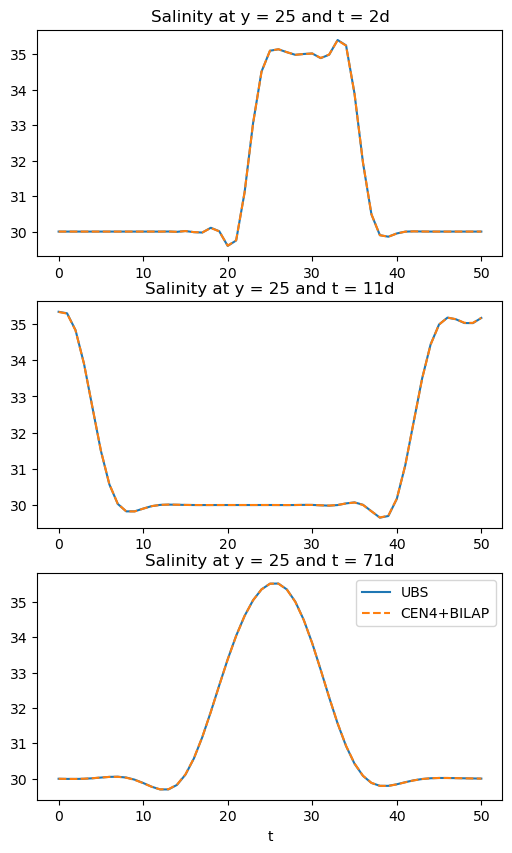

In [14]:
fig, ax = plt.subplots(3, 1, figsize=(6,10))

ax[0].plot(np.arange(51), ubs.isel(y_grid_T = 25, time_counter = 1),  label = 'UBS')
ax[0].plot(np.arange(51), cen4_bilap.isel(y_grid_T = 25, time_counter = 1), '--', label = 'CEN4+BILAP')

ax[1].plot(np.arange(51), ubs.isel(y_grid_T = 25, time_counter = 10),  label = 'UBS')
ax[1].plot(np.arange(51), cen4_bilap.isel(y_grid_T = 25, time_counter = 10), '--', label = 'CEN4+BILAP')


ax[2].plot(np.arange(51), ubs.isel(y_grid_T = 25, time_counter = 70),  label = 'UBS')
ax[2].plot(np.arange(51), cen4_bilap.isel(y_grid_T = 25, time_counter = 70), '--', label = 'CEN4+BILAP')

plt.legend()
ax[0].set_title('Salinity at y = 25 and t = 2d')
ax[1].set_title('Salinity at y = 25 and t = 11d')
ax[2].set_title('Salinity at y = 25 and t = 71d')
ax[2].set_xlabel('t')


In [25]:
err = abs(cen4_bilap-ubs)

In [26]:
epsilon = []
for e in err : 
    epsilon.append(float((e/ubs).mean())*100)

Text(0, 0.5, '% of error')

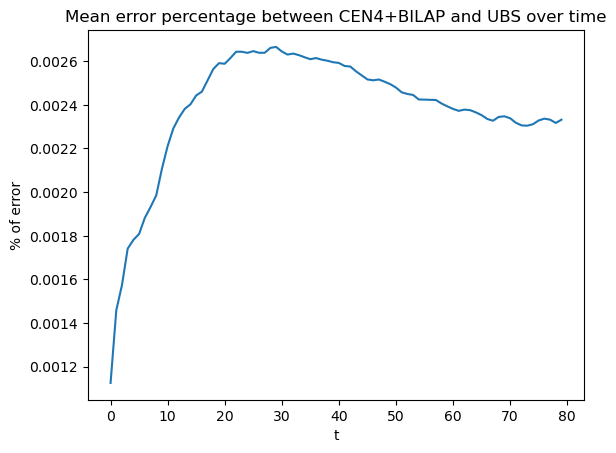

In [28]:
plt.plot(np.arange(80), epsilon)
plt.title('Mean error percentage between CEN4+BILAP and UBS over time')
plt.xlabel('t')
plt.ylabel('% of error')

The mean error at a fixed timeframe is of never over 0.04% of the 5ppt margin. 